# Room-sweep transformer: leave-one-out evaluation

Evaluates a `loo_roomsweeps.py` run (`Saved/loo_<run_id>/`). Each fold's model was trained without that
fold's data and is scored here only on the data it held out:

* `--fold_by experiment`: the held-out experiment. Training dropped every sample that shares a link location with it.
* `--fold_by columns`: the held-out block of grid columns. Training had no tag in those columns.

Every sample is held out in exactly one fold, so the pooled predictions cover the whole dataset, each made by a model
that never saw it. Each fold is compared against its own baselines, both computed from that fold's training data:
a **constant** (the per-ray train mean) and **1-NN fingerprint** (targets of the nearest training sample in the
model's own standardized features).

In [1]:
import glob
import importlib
import json
import os
import sys

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

HERE = os.path.abspath(".")
_cands = [HERE, os.path.join(HERE, "roomsweeps_ml"),
          os.path.join(HERE, "organized_multitag", "roomsweeps_processing", "roomsweeps_ml")]
HERE = next((d for d in _cands if os.path.isfile(os.path.join(d, "train_roomsweeps.py"))), None)
assert HERE, "launch from roomsweeps_ml/, roomsweeps_processing/ or the RFImaging root"
if HERE not in sys.path:
    sys.path.insert(0, HERE)

import train_roomsweeps as trs
importlib.reload(trs)
from train_roomsweeps import SAMPLE_KEYS, SUB_KEYS, WALL_DIRS, load_for_args, load_split, preprocess, scalers_from_checkpoint
from MLScripts.models.transformer import TagPairTransformer

MARKERS_CSV = os.path.join(HERE, "..", "..", "roomscans", "merged_markers.csv")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 60)

## Configuration

`LOO_DIR = None` picks the newest `Saved/loo_*` folder. `EVAL_MAX_GT_CM = None` scores only rays whose ground truth is
within the training `--dist_clip`, which is the range the clipped loss trains for. Set it to `np.inf` to score every ray.

In [2]:
LOO_DIR        = "/home/manaj/RFImaging/organized_multitag/roomsweeps_processing/roomsweeps_ml/Saved/loo_1120130944"
SAVED_DIR      = os.path.join(HERE, "Saved")
EVAL_FOLDS     = None      # fold names to evaluate, e.g. ["exp3", "exp8"] or ["col6-7-8"]; None → every finished fold
EVAL_MAX_GT_CM = None      # None → the training dist_clip
NN_BASELINE    = True
NN_MAX_TRAIN   = 200_000
ROOM_LIMIT     = 200       # sub-clusters per fold in the wall-hit plot

if LOO_DIR is None:
    _c = sorted(glob.glob(os.path.join(SAVED_DIR, "loo_*", "loo_manifest.json")), key=os.path.getmtime)
    if not _c:
        raise FileNotFoundError(f"no loo_* run in {SAVED_DIR}; run loo_roomsweeps.py first")
    LOO_DIR = os.path.dirname(_c[-1])
with open(os.path.join(LOO_DIR, "loo_manifest.json")) as f:
    manifest = json.load(f)
print("LOO run :", LOO_DIR)
print("dataset :", manifest["dataset"])
print("fold_by :", manifest["fold_by"], "  forwarded:", " ".join(manifest["forwarded_args"]) or "(defaults)")
display(pd.read_csv(os.path.join(LOO_DIR, "loo_summary.csv")))

LOO run : /home/manaj/RFImaging/organized_multitag/roomsweeps_processing/roomsweeps_ml/Saved/loo_1120130944
dataset : /home/manaj/RFImaging/organized_multitag/roomsweeps_processing/roomsweeps_ml/data/roomsweeps_K10_P1_span200cm_max1000.npz
fold_by : experiment   forwarded: --epochs 200


,fold,held_out,status,n_train,n_val,best_epoch,mae_dist_cm,mae_angle_deg,minutes,checkpoint
0,exp1,1,done,34860,2673,25,195.669876,27.553463,66.294782,ETF_rs_K10_45slots_alpha_nopos_valexp1_d128_l6...
1,exp2,2,done,32358,2673,57,178.217606,28.215878,63.731416,ETF_rs_K10_45slots_alpha_nopos_valexp2_d128_l6...
2,exp3,3,done,31419,2673,128,173.912170,29.181515,59.719199,ETF_rs_K10_45slots_alpha_nopos_valexp3_d128_l6...
3,exp4,4,done,32274,2673,21,171.887787,25.247288,64.026533,ETF_rs_K10_45slots_alpha_nopos_valexp4_d128_l6...
4,exp5,5,done,32274,2673,33,155.389114,26.142221,61.608712,ETF_rs_K10_45slots_alpha_nopos_valexp5_d128_l6...
5,exp6,6,done,32274,2673,29,159.013931,25.325336,61.313422,ETF_rs_K10_45slots_alpha_nopos_valexp6_d128_l6...
6,exp7,7,done,32274,2673,7,178.654465,25.757092,61.528727,ETF_rs_K10_45slots_alpha_nopos_valexp7_d128_l6...
7,exp8,8,done,32274,2673,12,171.781891,25.455414,62.070343,ETF_rs_K10_45slots_alpha_nopos_valexp8_d128_l6...
8,exp9,9,done,32274,2673,11,175.115082,24.482290,64.224622,ETF_rs_K10_45slots_alpha_nopos_valexp9_d128_l6...
9,exp10,10,done,32274,2673,48,165.567932,25.823168,60.110127,ETF_rs_K10_45slots_alpha_nopos_valexp10_d128_l...


## Fold models

Only finished folds are evaluated. A failed or still-running fold is listed and skipped; resume it with
`loo_roomsweeps.py --run_id <id>` and the same arguments.

17 folds: ['exp1', 'exp2', 'exp3', 'exp4', 'exp5', 'exp6', 'exp7', 'exp8', 'exp9', 'exp10', 'exp11', 'exp12', 'exp13', 'exp14', 'exp15', 'exp16', 'exp17']
features: ['theta', 'alpha'] (no positions)
scoring rays with GT ≤ 300 cm


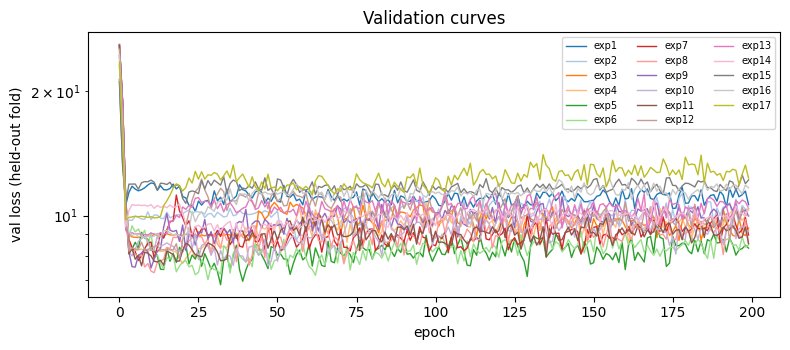

In [3]:
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
folds = {}
for fd in manifest["folds"]:
    r = manifest["results"].get(fd["name"], {})
    if EVAL_FOLDS is not None and fd["name"] not in EVAL_FOLDS:
        continue
    if r.get("status") != "done":
        print(f"[skip] {fd['name']}: {r.get('status', 'pending')}")
        continue
    with open(os.path.join(LOO_DIR, r["config"])) as f:
        cfg = json.load(f)
    folds[fd["name"]] = dict(fd=fd, cfg=cfg, ckpt_path=os.path.join(LOO_DIR, r["checkpoint"]))
FOLDS = list(folds)
assert FOLDS, "no finished folds to evaluate"
train_args = folds[FOLDS[0]]["cfg"]["args"]
DIST_CLIP = float(train_args.get("dist_clip", np.inf))
if EVAL_MAX_GT_CM is None:
    EVAL_MAX_GT_CM = DIST_CLIP
print(f"{len(FOLDS)} folds: {FOLDS}")
print("features:", list(folds[FOLDS[0]]["cfg"]["feature_slices"]),
      "(positions ON)" if train_args.get("include_positions") else "(no positions)")
print(f"scoring rays with GT ≤ {EVAL_MAX_GT_CM:g} cm")

fig, ax = plt.subplots(figsize=(8, 3.6))
for k, name in enumerate(FOLDS):
    c = folds[name]["cfg"]
    ax.plot(c["val_losses"], lw=1, color=plt.get_cmap("tab20")(k % 20), label=name)
ax.set_yscale("log"); ax.set_xlabel("epoch"); ax.set_ylabel("val loss (held-out fold)")
ax.set_title("Validation curves"); ax.legend(fontsize=7, ncol=3); plt.tight_layout(); plt.show()

## Run every fold model on its held-out data

In [4]:
data = load_for_args(train_args)
N = len(data.X_raw)


@torch.no_grad()
def predict(model, X, batch=2048):
    outs = [model(torch.from_numpy(np.ascontiguousarray(X[i:i + batch])).to(device), None)
            for i in range(0, len(X), batch)]
    return (np.concatenate([o[0].cpu().numpy() for o in outs]), np.concatenate([o[1].cpu().numpy() for o in outs]))


@torch.no_grad()
def nearest(Xq, Xr, batch=1024):
    R = torch.from_numpy(Xr.reshape(len(Xr), -1)).to(device)
    out = []
    for i in range(0, len(Xq), batch):
        q = torch.from_numpy(np.ascontiguousarray(Xq[i:i + batch]).reshape(-1, R.shape[1])).to(device)
        out.append(torch.cdist(q, R).argmin(1).cpu().numpy())
    return np.concatenate(out)


nanarr = lambda *s: np.full(s, np.nan, np.float32)   # noqa: E731
pred_d, pred_a = nanarr(N, 4), nanarr(N, 4)
const_d, nn_d, nn_a = nanarr(N, 4), nanarr(N, 4), nanarr(N, 4)
fold_of = np.full(N, "", dtype=object)
for name in FOLDS:
    f = folds[name]
    ckpt = torch.load(f["ckpt_path"], map_location=device, weights_only=False)
    model = TagPairTransformer(**f["cfg"]["model_config"])
    model.load_state_dict(ckpt["model_state_dict"]); model.to(device).eval()
    tr, va = load_split(os.path.join(LOO_DIR, f["cfg"]["split_file"]), data.meta_df)
    assert (fold_of[va] == "").all(), f"{name}: samples already held out by another fold"
    sp, _ = preprocess(data, tr, va, scalers=scalers_from_checkpoint(ckpt))
    pred_d[va], pred_a[va] = predict(model, sp["X_val"])
    const_d[va] = np.minimum(sp["Y_d_train"], DIST_CLIP).mean(0)
    if NN_BASELINE:
        ref = np.arange(len(tr))
        if len(ref) > NN_MAX_TRAIN:
            ref = np.sort(np.random.default_rng(0).choice(ref, NN_MAX_TRAIN, replace=False))
        j = ref[nearest(sp["X_val"], sp["X_train"][ref])]
        nn_d[va], nn_a[va] = sp["Y_d_train"][j], sp["Y_a_train"][j]
    fold_of[va] = name
    f.update(n_train=len(tr), n_val=len(va))
    del sp, model
    print(f"{name}: train {len(tr)}, held out {len(va)}")

held = fold_of != ""
meta = data.meta_df[held].reset_index(drop=True)
meta.insert(0, "sample_idx", np.flatnonzero(held))
meta["fold"] = fold_of[held]
idx = np.flatnonzero(held)
true_d, true_a = data.Y_dists[idx], data.Y_angles[idx]
pred_d, pred_a, const_d = pred_d[idx], pred_a[idx], const_d[idx]
nn_d, nn_a = (nn_d[idx], nn_a[idx]) if NN_BASELINE else (None, None)
fcol = meta["fold"].to_numpy()
SCORED = true_d <= EVAL_MAX_GT_CM
print(f"\n{held.sum()} of {N} samples held out by an evaluated fold; "
      f"{np.mean(~SCORED):.1%} of their rays are beyond {EVAL_MAX_GT_CM:g} cm (not scored)")

[loader] 15147 sub-clusters × 3 run(s) → 45441 samples, n_pairs=45, n_freq=22, feat_dim=44 ['theta', 'alpha'], frame=local, experiments=[1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17]
[preprocess] train=(34860, 45, 44)  val=(2673, 45, 44)  Y_d mean=[380.  378.1 355.9 352.7]
exp1: train 34860, held out 2673
[preprocess] train=(32358, 45, 44)  val=(2673, 45, 44)  Y_d mean=[380.5 377.2 356.1 352.3]
exp2: train 32358, held out 2673
[preprocess] train=(31419, 45, 44)  val=(2673, 45, 44)  Y_d mean=[378.6 377.1 353.7 351.5]
exp3: train 31419, held out 2673
[preprocess] train=(32274, 45, 44)  val=(2673, 45, 44)  Y_d mean=[376.3 373.4 349.2 347.8]
exp4: train 32274, held out 2673
[preprocess] train=(32274, 45, 44)  val=(2673, 45, 44)  Y_d mean=[373.9 370.3 346.9 345.3]
exp5: train 32274, held out 2673
[preprocess] train=(32274, 45, 44)  val=(2673, 45, 44)  Y_d mean=[371.6 369.5 345.7 343.5]
exp6: train 32274, held out 2673
[preprocess] train=(32274, 45, 44)  val=(2673, 45, 44)  Y_d 

## Metrics per fold

Distances are in cm and angles in degrees, over scored rays. `gain_vs_*` = baseline MAE − model MAE, so positive
means the model beats that baseline. **ALL (pooled)** weighs every sample equally. **MEAN (per fold)** weighs every
fold equally.

In [5]:
def _mae(p, t, m):
    return float(np.nanmean(np.where(m, np.abs(p - t), np.nan))) if m.any() else np.nan


def metrics_for(sel):
    m = SCORED[sel]
    a = np.where(m, np.abs(pred_d[sel] - true_d[sel]), np.nan)
    n_s = max(m.sum(), 1)
    out = {"n": int(sel.sum()),
           "mae_dist_cm": float(np.nanmean(a)),
           "const_cm": _mae(const_d[sel], true_d[sel], m),
           "medae_dist_cm": float(np.nanmedian(a)),
           "p90_dist_cm": float(np.nanpercentile(a, 90)),
           "bias_dist_cm": float(np.nanmean(np.where(m, pred_d[sel] - true_d[sel], np.nan))),
           "acc<=10cm": float((a <= 10).sum() / n_s),
           "acc<=20cm": float((a <= 20).sum() / n_s),
           "acc<=50cm": float((a <= 50).sum() / n_s),
           "gt_dist_cm": float(np.nanmean(np.where(m, true_d[sel], np.nan))),
           "mae_angle_deg": float(np.mean(np.abs(pred_a[sel] - true_a[sel])))}
    out["gain_vs_const"] = out["const_cm"] - out["mae_dist_cm"]
    if nn_d is not None:
        out["nn1_cm"] = _mae(nn_d[sel], true_d[sel], m)
        out["gain_vs_nn1"] = out["nn1_cm"] - out["mae_dist_cm"]
    for j, w in enumerate(WALL_DIRS):
        out[f"mae_{w}_cm"] = _mae(pred_d[sel, j], true_d[sel, j], m[:, j])
    return out


loo_tbl = pd.DataFrame({name: metrics_for(fcol == name) | {"n_train": folds[name]["n_train"],
                                                           "best_epoch": folds[name]["cfg"]["best_epoch"]}
                        for name in FOLDS}).T
mean_row = loo_tbl.mean(numeric_only=True)
loo_tbl.loc["ALL (pooled)"] = pd.Series(metrics_for(np.ones(len(fcol), bool)))
loo_tbl.loc["MEAN (per fold)"] = mean_row
_cols = [c for c in ["n", "n_train", "best_epoch", "mae_dist_cm", "const_cm", "nn1_cm", "gain_vs_const",
                     "gain_vs_nn1", "medae_dist_cm", "p90_dist_cm", "bias_dist_cm", "acc<=10cm", "acc<=20cm",
                     "acc<=50cm", "gt_dist_cm", "mae_angle_deg"] if c in loo_tbl]
_fmt = {c: "{:.1f}" for c in _cols} | {c: "{:.1%}" for c in _cols if c.startswith("acc")}
_fmt |= {"n": "{:.0f}", "n_train": "{:.0f}", "best_epoch": "{:.0f}", "gain_vs_const": "{:+.1f}", "gain_vs_nn1": "{:+.1f}"}
display(loo_tbl[_cols].style.format(_fmt, na_rep="")
        .background_gradient(subset=["mae_dist_cm"], cmap="RdYlGn_r")
        .background_gradient(subset=[c for c in ["gain_vs_const", "gain_vs_nn1"] if c in _cols], cmap="RdYlGn")
        .set_caption(f"Held-out accuracy per fold ({manifest['fold_by']})"))

,n,n_train,best_epoch,mae_dist_cm,const_cm,nn1_cm,gain_vs_const,gain_vs_nn1,medae_dist_cm,p90_dist_cm,bias_dist_cm,acc<=10cm,acc<=20cm,acc<=50cm,gt_dist_cm,mae_angle_deg
exp1,2673,34860,25,98.4,95.9,229.8,-2.5,+131.3,98.7,183.3,92.1,8.4%,15.7%,31.8%,148.3,27.6
exp2,2673,32358,57,74.7,74.9,210.4,+0.2,+135.7,67.2,146.6,59.0,12.9%,23.4%,42.6%,170.9,28.2
exp3,2673,31419,128,69.1,60.8,210.8,-8.3,+141.7,66.2,138.2,49.8,10.2%,19.7%,40.5%,184.9,29.2
exp4,2673,32274,21,74.5,57.4,205.1,-17.1,+130.7,60.3,154.3,62.6,6.9%,15.7%,39.8%,194.6,25.2
exp5,2673,32274,33,48.0,68.5,200.9,+20.6,+152.9,29.1,123.9,32.7,17.6%,37.3%,66.7%,192.0,26.1
exp6,2673,32274,29,60.6,73.6,209.2,+13.0,+148.6,43.2,144.8,43.6,15.3%,28.4%,54.5%,165.5,25.3
exp7,2673,32274,7,124.3,73.6,206.1,-50.7,+81.9,133.3,173.7,123.9,3.1%,4.9%,9.4%,165.8,25.8
exp8,2673,32274,12,76.1,72.7,189.4,-3.5,+113.3,72.2,138.6,69.0,5.7%,11.7%,34.2%,166.7,25.5
exp9,2673,32274,11,86.9,73.6,200.2,-13.3,+113.3,81.4,163.9,82.2,5.4%,11.4%,30.3%,164.8,24.5
exp10,2673,32274,48,63.6,71.9,209.1,+8.3,+145.5,44.1,155.9,42.8,17.2%,30.6%,53.4%,167.5,25.8


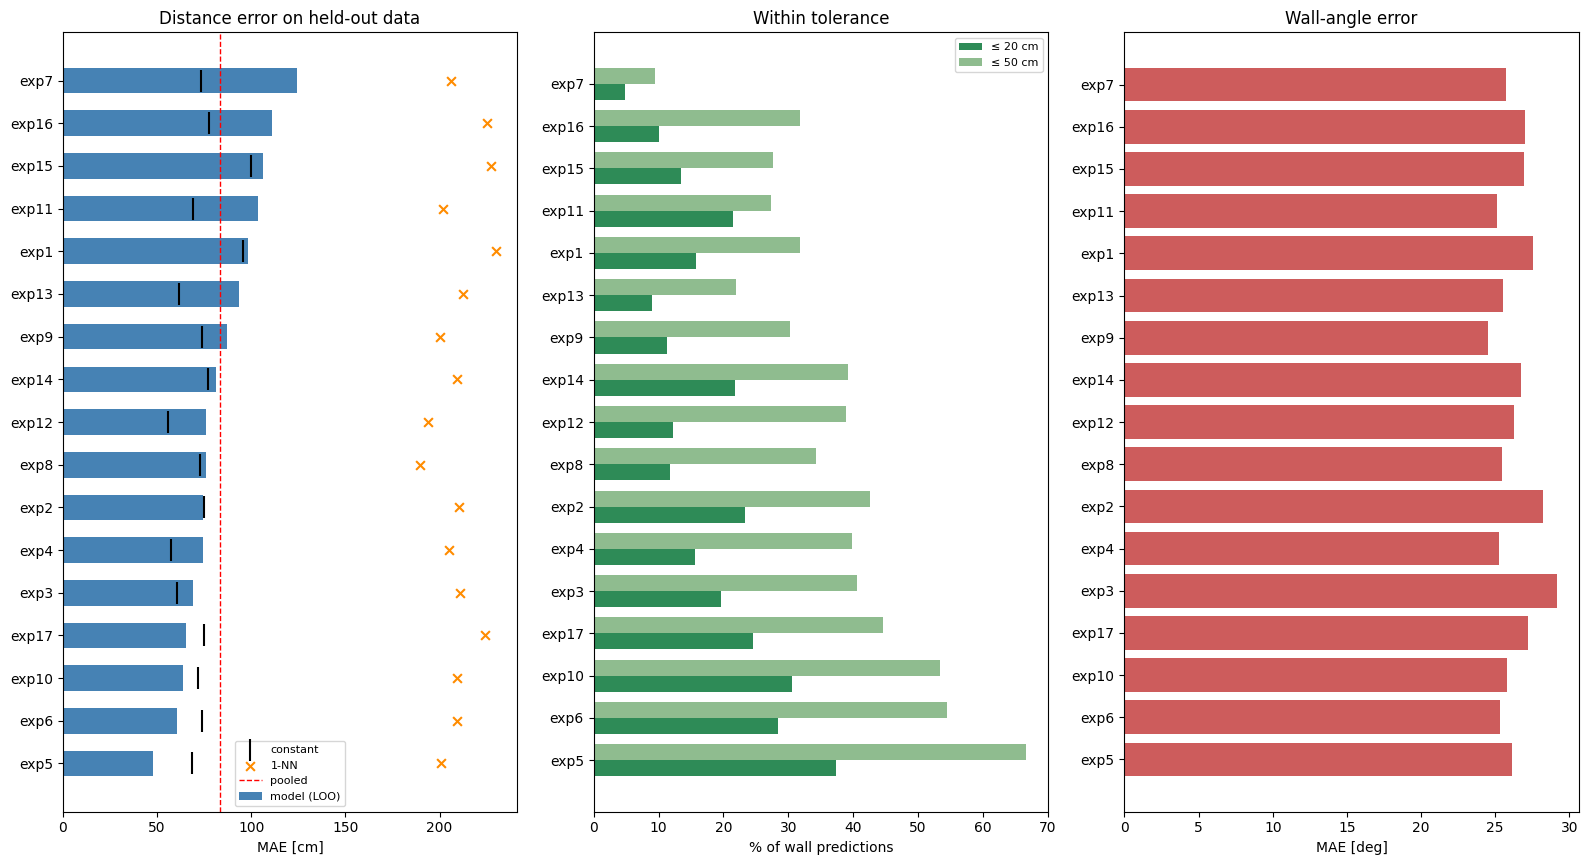

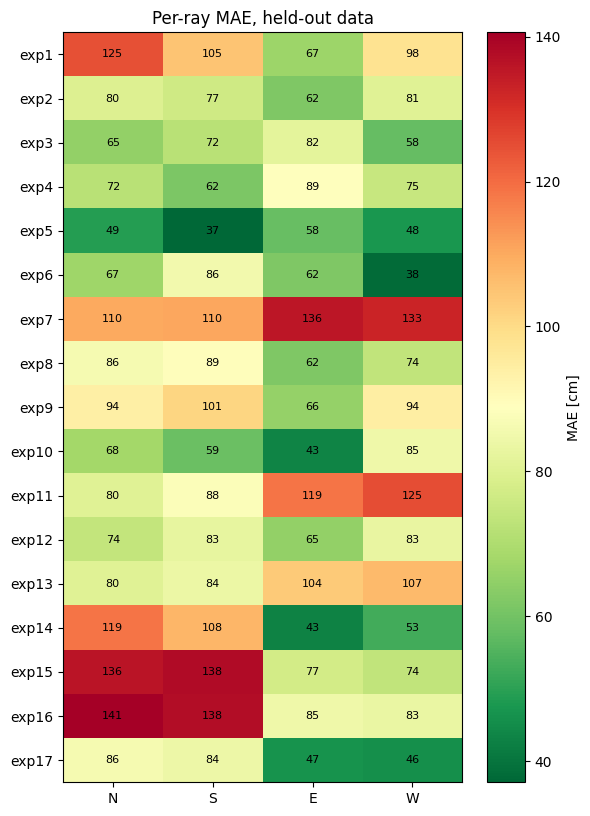

In [6]:
plot_tbl = loo_tbl.loc[FOLDS].sort_values("mae_dist_cm")
y = np.arange(len(plot_tbl))
fig, axes = plt.subplots(1, 3, figsize=(16, 0.35 * len(plot_tbl) + 2.8))
ax = axes[0]
ax.barh(y, plot_tbl["mae_dist_cm"], height=0.6, color="steelblue", label="model (LOO)")
ax.scatter(plot_tbl["const_cm"], y, marker="|", s=250, color="k", zorder=5, label="constant")
if "nn1_cm" in plot_tbl:
    ax.scatter(plot_tbl["nn1_cm"], y, marker="x", s=40, color="darkorange", zorder=5, label="1-NN")
ax.axvline(loo_tbl.loc["ALL (pooled)", "mae_dist_cm"], color="red", ls="--", lw=1, label="pooled")
ax.set_yticks(y, plot_tbl.index); ax.set_xlabel("MAE [cm]"); ax.set_title("Distance error on held-out data")
ax.legend(fontsize=8)
ax = axes[1]
ax.barh(y - 0.19, plot_tbl["acc<=20cm"] * 100, height=0.38, color="seagreen", label="≤ 20 cm")
ax.barh(y + 0.19, plot_tbl["acc<=50cm"] * 100, height=0.38, color="darkseagreen", label="≤ 50 cm")
ax.set_yticks(y, plot_tbl.index); ax.set_xlabel("% of wall predictions"); ax.set_title("Within tolerance")
ax.legend(fontsize=8)
ax = axes[2]
ax.barh(y, plot_tbl["mae_angle_deg"], color="indianred")
ax.set_yticks(y, plot_tbl.index); ax.set_xlabel("MAE [deg]"); ax.set_title("Wall-angle error")
plt.tight_layout(); plt.show()

wall_mat = loo_tbl.loc[FOLDS, [f"mae_{w}_cm" for w in WALL_DIRS]].astype(float)
fig, ax = plt.subplots(figsize=(6, 0.38 * len(wall_mat) + 1.8))
im = ax.imshow(wall_mat.values, cmap="RdYlGn_r", aspect="auto")
ax.set_xticks(range(4), WALL_DIRS); ax.set_yticks(range(len(wall_mat)), wall_mat.index)
for i in range(wall_mat.shape[0]):
    for j in range(4):
        ax.text(j, i, f"{wall_mat.values[i, j]:.0f}", ha="center", va="center", fontsize=8)
plt.colorbar(im, ax=ax, label="MAE [cm]"); ax.set_title("Per-ray MAE, held-out data")
plt.tight_layout(); plt.show()

### Prediction vs ground truth, per fold

The grey band marks ground truth beyond `EVAL_MAX_GT_CM`. Those rays aren't scored.

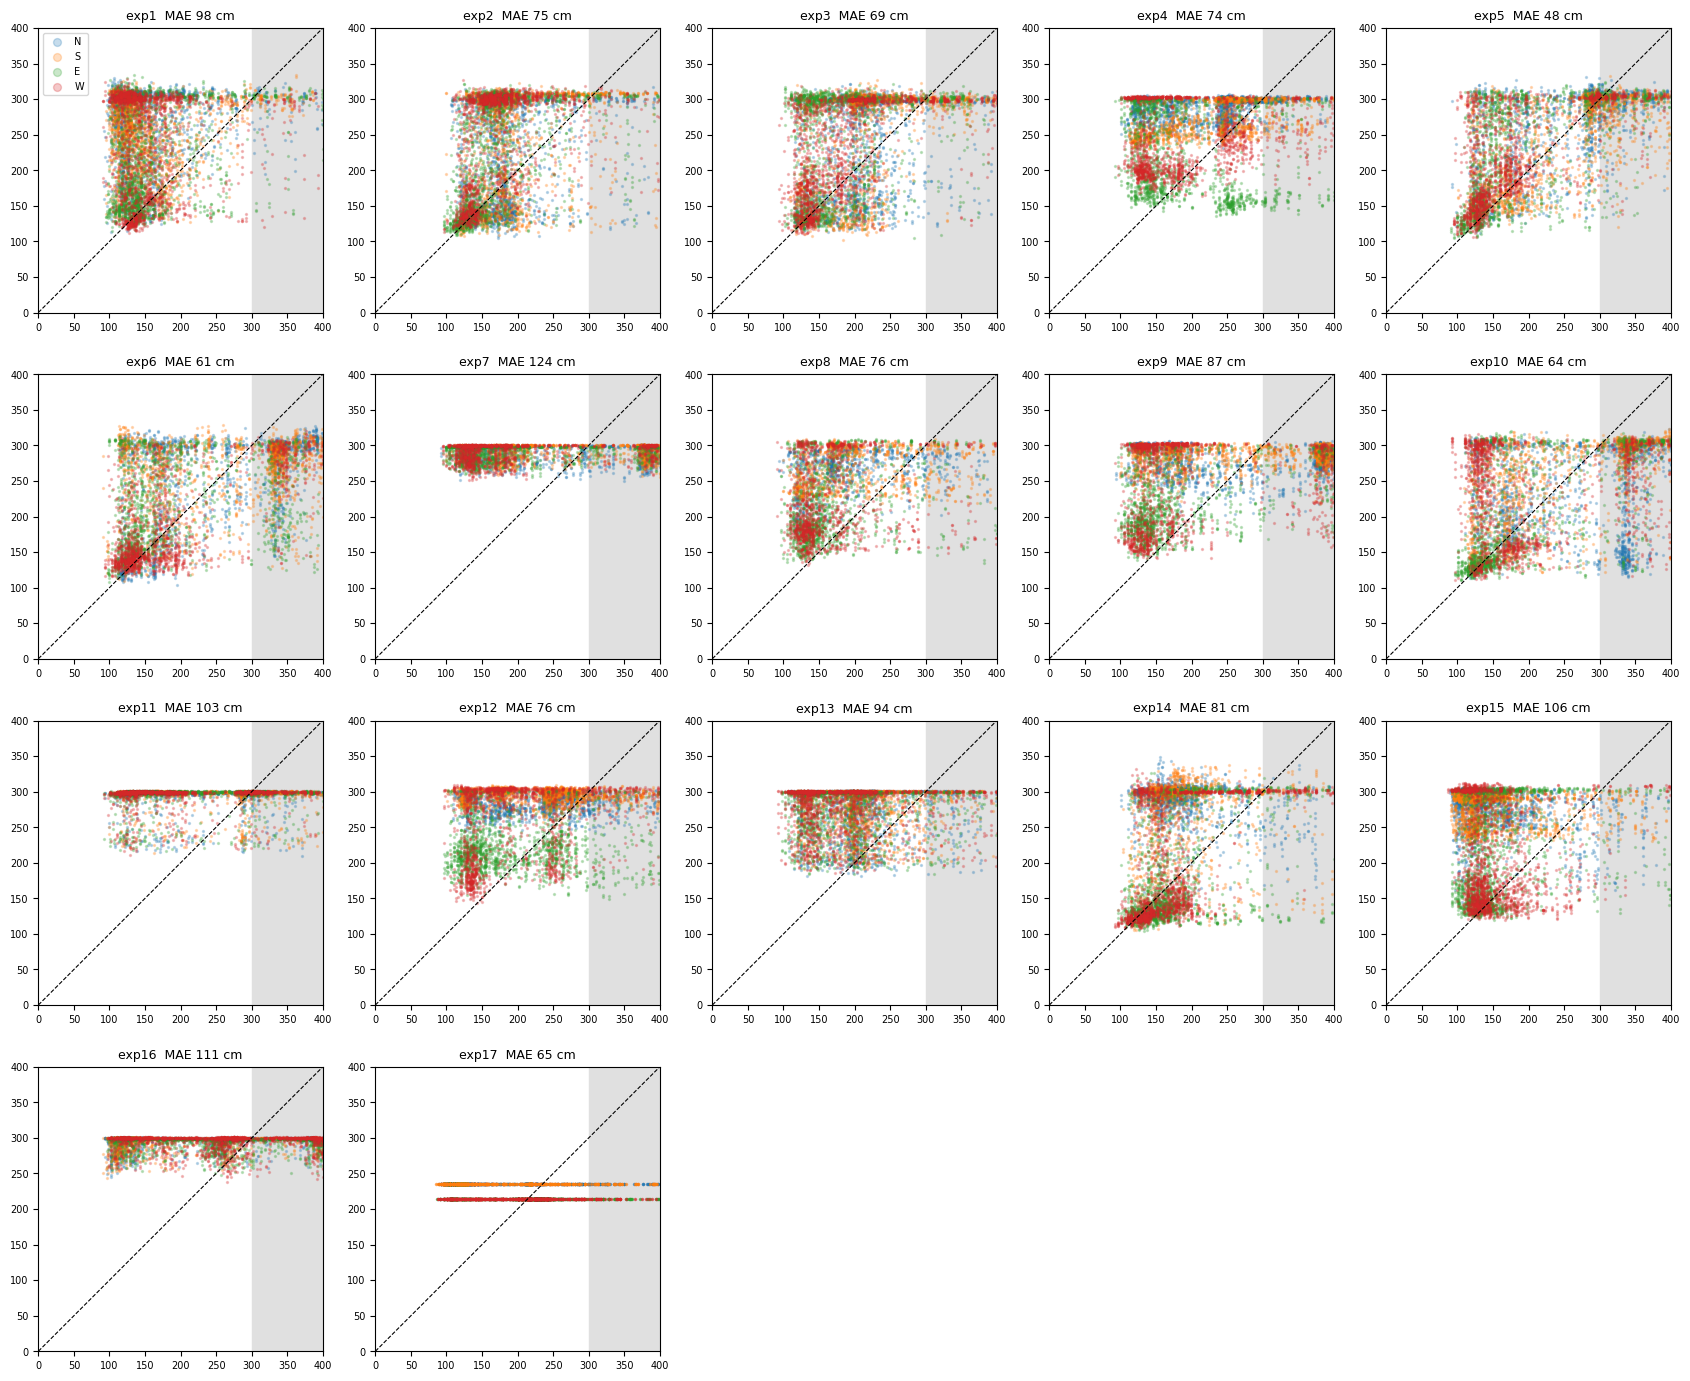

In [7]:
lim = float(np.ceil(min(true_d.max(), 1.3 * EVAL_MAX_GT_CM) / 50) * 50)
ncol = 5
nrow = int(np.ceil(len(FOLDS) / ncol))
fig, axes = plt.subplots(nrow, ncol, figsize=(3.4 * ncol, 3.5 * nrow), squeeze=False)
for ax, name in zip(axes.flat, FOLDS):
    s = fcol == name
    for j, w in enumerate(WALL_DIRS):
        ax.scatter(true_d[s, j], np.clip(pred_d[s, j], 0, lim), s=2, alpha=0.25, label=w)
    ax.plot([0, lim], [0, lim], "k--", lw=0.8)
    if EVAL_MAX_GT_CM < lim:
        ax.axvspan(EVAL_MAX_GT_CM, lim, color="0.88", zorder=0)
    ax.set_xlim(0, lim); ax.set_ylim(0, lim); ax.set_aspect("equal"); ax.tick_params(labelsize=7)
    ax.set_title(f"{name}  MAE {loo_tbl.loc[name, 'mae_dist_cm']:.0f} cm", fontsize=9)
axes.flat[0].legend(fontsize=7, markerscale=4)
for ax in axes.flat[len(FOLDS):]:
    ax.axis("off")
plt.tight_layout(); plt.show()

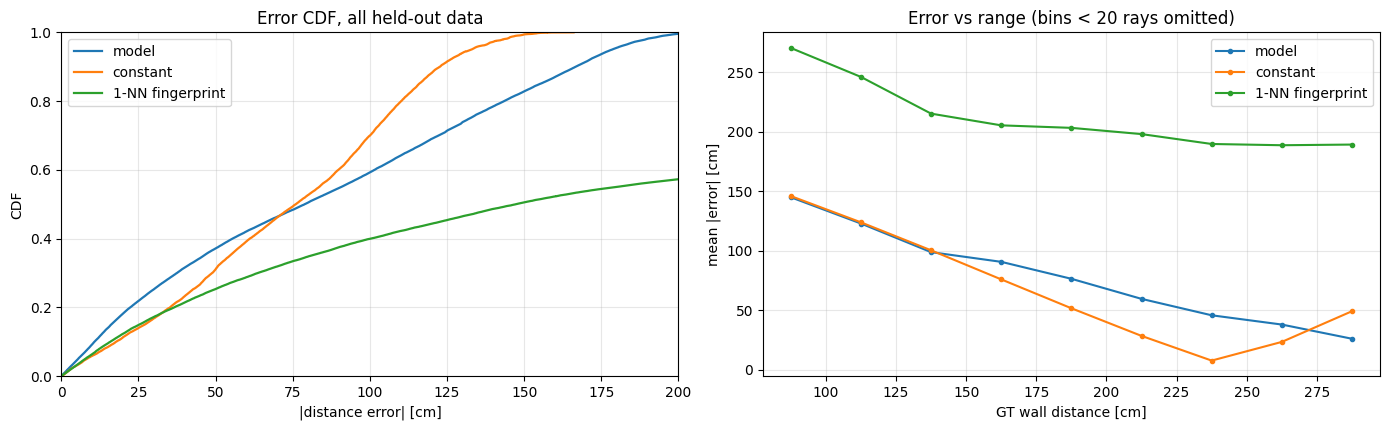

In [8]:
summary = {"model": pred_d, "constant": const_d}
if nn_d is not None:
    summary["1-NN fingerprint"] = nn_d
fig, axes = plt.subplots(1, 2, figsize=(14, 4.4))
ax = axes[0]
for k, d in summary.items():
    e = np.sort(np.abs(d - true_d)[SCORED])
    ax.plot(e, np.arange(1, len(e) + 1) / len(e), lw=1.6, label=k)
ax.set_xlim(0, 200); ax.set_ylim(0, 1); ax.grid(alpha=0.3)
ax.set_xlabel("|distance error| [cm]"); ax.set_ylabel("CDF"); ax.set_title("Error CDF, all held-out data"); ax.legend()
ax = axes[1]
edges = np.arange(0, min(true_d.max(), EVAL_MAX_GT_CM) + 25, 25)
cent = 0.5 * (edges[:-1] + edges[1:])
b = np.digitize(true_d, edges) - 1
for k, d in summary.items():
    e = np.abs(d - true_d)
    ax.plot(cent, [e[(b == i) & SCORED].mean() if ((b == i) & SCORED).sum() >= 20 else np.nan
                   for i in range(len(cent))], marker="o", ms=3, label=k)
ax.set_xlabel("GT wall distance [cm]"); ax.set_ylabel("mean |error| [cm]")
ax.set_title("Error vs range (bins < 20 rays omitted)"); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout(); plt.show()

## The room

Everything is in the merged-scan frame shared by all experiments: the outline is the four walls from
`find_walls()`, and the dots are the floor labels. The first figure shows every held-out sub-cluster's
centroid, coloured by the error of the fold model that never saw it. That shows where in the room the
approach works. The second shows the predicted wall hits, coloured by fold.

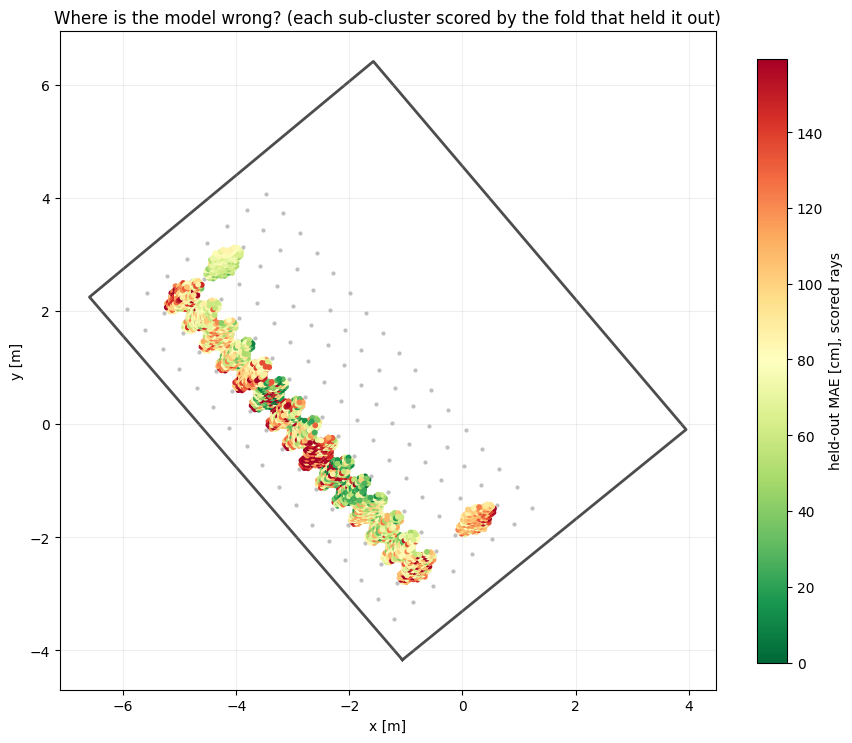

In [9]:
room = data.room
WP, WN = np.asarray(room["wall_points"]), np.asarray(room["wall_normals"])
_ix = {n: i for i, n in enumerate(room["wall_names"])}
_ring = [_ix["Edge02 wall"], _ix["Row-1 wall"], _ix["Edge01 wall"], _ix["Row-8 wall"]]


def _corner(i, j):
    return np.linalg.solve(np.stack([WN[i], WN[j]]), [WN[i] @ WP[i], WN[j] @ WP[j]])


ROOM_POLY = np.array([_corner(_ring[k], _ring[(k + 1) % 4]) for k in range(4)] + [_corner(_ring[0], _ring[1])])
markers = pd.read_csv(MARKERS_CSV).set_index("index").sort_index() if os.path.isfile(MARKERS_CSV) else None
FOLD_COLORS = {n: plt.get_cmap("tab20")(k % 20) for k, n in enumerate(FOLDS)}


def draw_room(ax):
    ax.plot(ROOM_POLY[:, 0], ROOM_POLY[:, 1], color="0.3", lw=2, zorder=1)
    if markers is not None:
        ax.scatter(markers["x"], markers["y"], s=4, c="0.75", zorder=1)
    ax.set_aspect("equal"); ax.set_xlabel("x [m]"); ax.set_ylabel("y [m]"); ax.grid(alpha=0.2)


err = np.nanmean(np.where(SCORED, np.abs(pred_d - true_d), np.nan), axis=1)
loc = (meta.assign(err=err).groupby(["experiment", "combination_id"], as_index=False)
       .agg(x=("centroid_x", "first"), y=("centroid_y", "first"), err=("err", "mean"), fold=("fold", "first")))
fig, ax = plt.subplots(figsize=(9, 8))
draw_room(ax)
sc = ax.scatter(loc["x"], loc["y"], c=loc["err"], cmap="RdYlGn_r", s=10, vmin=0,
                vmax=np.nanpercentile(loc["err"], 95), zorder=3)
plt.colorbar(sc, ax=ax, label="held-out MAE [cm], scored rays", shrink=0.8)
ax.set_title("Where is the model wrong? (each sub-cluster scored by the fold that held it out)")
plt.tight_layout(); plt.show()

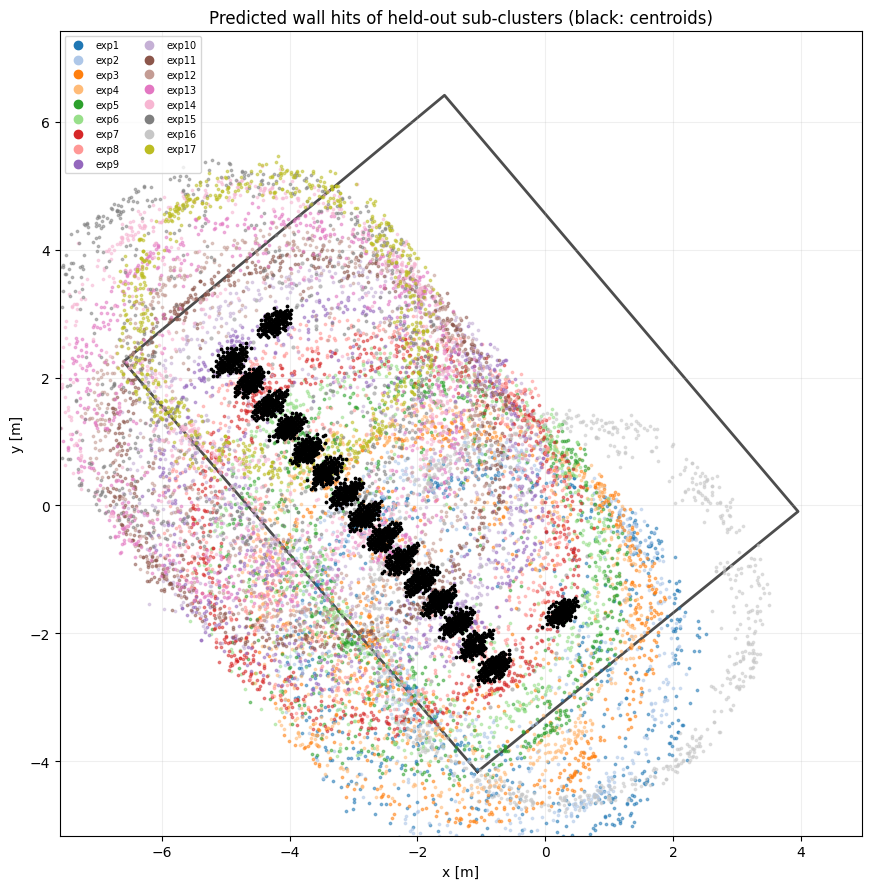

In [10]:
rng = np.random.default_rng(0)
first = ~meta.duplicated(SUB_KEYS[:2]).to_numpy()
dirs = data.ray_dirs[idx][:, :, :2]
cxy = data.centroids[idx][:, :2]
fig, ax = plt.subplots(figsize=(10, 9))
draw_room(ax)
for name in FOLDS:
    cand = np.flatnonzero((fcol == name) & first)
    pick = rng.choice(cand, min(ROOM_LIMIT, len(cand)), replace=False)
    hits = cxy[pick, None] + np.clip(pred_d[pick], 0, None)[..., None] / 100 * dirs[pick]
    ax.scatter(hits[..., 0].ravel(), hits[..., 1].ravel(), s=3, alpha=0.5, color=FOLD_COLORS[name], zorder=2)
    ax.scatter(cxy[pick, 0], cxy[pick, 1], s=3, color="k", zorder=3)
pad = 1.0
ax.set_xlim(ROOM_POLY[:, 0].min() - pad, ROOM_POLY[:, 0].max() + pad)
ax.set_ylim(ROOM_POLY[:, 1].min() - pad, ROOM_POLY[:, 1].max() + pad)
ax.legend(handles=[Line2D([], [], ls="", marker="o", color=c, label=n) for n, c in FOLD_COLORS.items()],
          fontsize=7, ncol=2, loc="upper left")
ax.set_title("Predicted wall hits of held-out sub-clusters (black: centroids)")
plt.tight_layout(); plt.show()

## Export

In [11]:
loo_tbl.rename_axis("fold").to_csv(os.path.join(LOO_DIR, "loo_perfold_eval.csv"))
_p = meta[["sample_idx", "fold"] + SAMPLE_KEYS + ["tags", "labels", "centroid_x", "centroid_y"]].copy()
for j, w in enumerate(WALL_DIRS):
    _p[f"gt_dist_{w}_cm"], _p[f"pred_dist_{w}_cm"] = true_d[:, j], pred_d[:, j]
    _p[f"const_dist_{w}_cm"] = const_d[:, j]
    if nn_d is not None:
        _p[f"nn1_dist_{w}_cm"] = nn_d[:, j]
    _p[f"gt_angle_{w}_deg"], _p[f"pred_angle_{w}_deg"] = true_a[:, j], pred_a[:, j]
_p.to_csv(os.path.join(LOO_DIR, "loo_val_predictions.csv"), index=False)
print("Per-fold metrics →", os.path.join(LOO_DIR, "loo_perfold_eval.csv"))
print("Predictions      →", os.path.join(LOO_DIR, "loo_val_predictions.csv"))

Per-fold metrics → /home/manaj/RFImaging/organized_multitag/roomsweeps_processing/roomsweeps_ml/Saved/loo_1120130944/loo_perfold_eval.csv
Predictions      → /home/manaj/RFImaging/organized_multitag/roomsweeps_processing/roomsweeps_ml/Saved/loo_1120130944/loo_val_predictions.csv
